<a id='notebook-top'></a>

# Preview of the Coordinated Observations
---
This notebook shows the observations around and above the pore in the photosphere, from the chromosphere to the corona, by the key instruments on 2022 October 20, including DKIST/VBI, DKIST/ViSP, IRIS, and SolO/EUI HRIEUV.

Go to [Figure 2](#figure-2). 

Note: The internal hyperlink only works on [GitHub Pages](https://yjzhu-solar.github.io/DKIST_SolO_Fibril/ipynb_html/all_channel_layout.html) or [nbviewer](https://nbviewer.org/github/yjzhu-solar/DKIST_SolO_Fibril/blob/master/ipynb/ms_plot/all_channel_layout.ipynb). Do not click when viewing the notebook on GitHub.

## Import libraries and plotting configurations

In [15]:
import numpy as np 
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
from matplotlib.patches import Polygon
import sunpy
import sunpy.map
from sunpy.coordinates import get_earth, propagate_with_solar_surface
import dkist 
import dask.array as da
import h5py
from astropy.time import Time
from astropy.io import ascii, fits
from astropy.wcs import WCS
from astropy.visualization import (ImageNormalize, 
                    SqrtStretch, AsinhStretch,
                    ZScaleInterval, SinhStretch)
import astropy.units as u
from ndcube import NDCube
from ndcube.wcs.tools import unwrap_wcs_to_fitswcs
from fancy_colorbar import wcs_scalebar
from IPython.display import HTML, display
import slit_interactive_plus as sip

In [3]:
ms_style_dict = {'text.usetex': True, 'font.family': 'serif', 'axes.linewidth': 1.2,
                 'xtick.major.width': 1.2, 'xtick.major.size': 4,
                 'ytick.major.width': 1.2, 'ytick.major.size': 4,
                 'xtick.minor.width': 1.2, 'xtick.minor.size': 2,
                 'ytick.minor.width': 1.2, 'ytick.minor.size': 2,
                 'xtick.direction': 'in', 'ytick.direction': 'in',
                 'text.latex.preamble': r'\usepackage[T1]{fontenc}'
                 r'\usepackage{amsmath}' r'\usepackage{siunitx}'
                 r'\sisetup{detect-all=True}' r'\usepackage{fixltx2e}'}

## Load preprocessed data

In [50]:
# load all plot-ready dataset, including data (in dask arrays), wcs and date_obs

file_Gband_pr = h5py.File("../../data/pid_1_123_aux/plot_ready/Gband_AEZDV_pr.hdf5")
Gband_pr_set = file_Gband_pr["vbi_img"]
Gband_pr_da = da.from_array(Gband_pr_set, chunks=(1, 4096 - 128*2, 4096 - 128*2))
Gband_date_obs = Time(ascii.read("../../data/pid_1_123_aux/plot_ready/Gband_AEZDV_date_avg.txt")["DATE-AVG"])

file_Hbeta_pr = h5py.File("../../data/pid_1_123_aux/plot_ready/Hbeta_BJOLO_pr.hdf5")
Hbeta_pr_set = file_Hbeta_pr["vbi_img"]
Hbeta_pr_da = da.from_array(Hbeta_pr_set, chunks=(1, 4096 - 128*2, 4096 - 128*2))
Hbeta_date_obs = Time(ascii.read("../../data/pid_1_123_aux/plot_ready/Hbeta_BJOLO_date_avg.txt")["DATE-AVG"])

file_CaIIK_pr = h5py.File("../../data/pid_1_123_aux/plot_ready/CaIIK_BZPOW_pr.hdf5")
CaIIK_pr_set = file_CaIIK_pr["vbi_img"]
CaIIK_pr_da = da.from_array(CaIIK_pr_set, chunks=(1, 4096 - 128*2, 4096 - 128*2))
CaIIK_date_obs = Time(ascii.read("../../data/pid_1_123_aux/plot_ready/CaIIK_BZPOW_date_avg.txt")["DATE-AVG"])

file_TiO_pr = h5py.File("../../data/pid_1_123_aux/plot_ready/TiO_BNRPZ_pr.hdf5")
TiO_pr_set = file_TiO_pr["vbi_img"]
TiO_pr_da = da.from_array(TiO_pr_set, chunks=(1, 4096 - 128*2, 4096 - 128*2))
TiO_date_obs = Time(ascii.read("../../data/pid_1_123_aux/plot_ready/TiO_BNRPZ_date_avg.txt")["DATE-AVG"])

file_Halpha_pr = h5py.File("../../data/pid_1_123_aux/plot_ready/Halpha_BLZNL_pr.hdf5")
Halpha_pr_set = file_Halpha_pr["vbi_img"]
Halpha_pr_da = da.from_array(Halpha_pr_set, chunks=(1, 4096 - 128*2, 4096 - 128*2))
Halpha_date_obs = Time(ascii.read("../../data/pid_1_123_aux/plot_ready/Halpha_BLZNL_date_avg.txt")["DATE-AVG"])


file_hri_pr_dset = h5py.File("../../data/pid_1_123_aux/plot_ready/HRIEUV_pr.hdf5")
hri_pr_set = file_hri_pr_dset["hrieuv_img"]
hri_pr_da = da.from_array(hri_pr_set, chunks=(1, (4096 - 128*2)//8, (4096 - 128*2)//8))


file_hri_pr_noproj_dset = h5py.File("../../data/pid_1_123_aux/plot_ready/HRIEUV_noproj_pr.hdf5")
hri_pr_noproj_array = file_hri_pr_noproj_dset["hrieuv_noproj_img"][:]
hrieuv_no_proj_extent = np.load("../../data/pid_1_123_aux/plot_ready/hrieuv_no_proj_extent.npy")
hrieuv_nocrop_noproj_wcs = WCS(fits.getheader("../../data/pid_1_123_aux/plot_ready/hri_nocrop_noproj_wcs.fits",
                                        ignore_missing_simple=True))
hrieuv_noproj_wcs = hrieuv_nocrop_noproj_wcs[hrieuv_no_proj_extent[1]:hrieuv_no_proj_extent[3] + 1,
                                hrieuv_no_proj_extent[0]:hrieuv_no_proj_extent[2] + 1]


hrieuv_date_ear = Time(ascii.read("../../data/pid_1_123_aux/plot_ready/HRIEUV_date_ear.txt")["date_ear"])


file_irissji_pr_dset = h5py.File("../../data/pid_1_123_aux/plot_ready/IRISSJI_1400_pr.hdf5")
irissji_pr_set = file_irissji_pr_dset["irissji_1400_img"]
irissji_pr_da = da.from_array(irissji_pr_set, chunks=(1, (4096 - 128*2)//8, (4096 - 128*2)//8))
irissji_date_obs = Time(ascii.read("../../data/pid_1_123_aux/plot_ready/IRISSJI_1400_date_obs.txt")["date_obs"])


file_aia171_pr_dset = h5py.File("../../data/pid_1_123_aux/plot_ready/AIA_171_pr.hdf5")
aia171_pr_set = file_aia171_pr_dset["aia_171_img"]
aia171_pr_da = da.from_array(aia171_pr_set, chunks=(1, (4096 - 128*2)//8, (4096 - 128*2)//8))
aia171_date_obs = Time(ascii.read("../../data/pid_1_123_aux/plot_ready/AIA_171_date_obs.txt")["date_obs"])


dkist_vbi_target_header = fits.getheader("../../data/pid_1_123_aux/plot_ready/dkist_target_wcs_header_before_crop.fits",
                                        ignore_missing_simple=True)
dkist_vbi_target_header["rsun_ref"] = 695700000 + 4.7e6
dkist_vbi_target_data = np.zeros((4096,4096))

dkist_vbi_target_cube = NDCube(dkist_vbi_target_data,WCS(dkist_vbi_target_header, naxis=2))
dkist_vbi_target_cube_crop = dkist_vbi_target_cube[128:-128,128:-128]
dkist_vbi_target_cube_crop_rebin = dkist_vbi_target_cube_crop.rebin((8,8))

target_wcs = dkist_vbi_target_cube_crop.wcs
target_wcs = unwrap_wcs_to_fitswcs(target_wcs)[0]
target_wcs_rebin = dkist_vbi_target_cube_crop_rebin.wcs

Set MJD-BEG to 59876.791095 from DATE-BEG.
Set MJD-AVG to 59876.791095 from DATE-AVG.
Set MJD-END to 59876.791095 from DATE-END'. [astropy.wcs.wcs]
Set OBSGEO-B to    20.706700 from OBSGEO-[XYZ].
Set OBSGEO-H to     3063.997 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


In [6]:
hrieuv_index_ = 105
iris_index_ = np.nanargmin(np.abs(hrieuv_date_ear[hrieuv_index_] - irissji_date_obs))
Halpha_index_ = np.nanargmin(np.abs(hrieuv_date_ear[hrieuv_index_] - Halpha_date_obs))
Hbeta_index_ = np.nanargmin(np.abs(hrieuv_date_ear[hrieuv_index_] - Hbeta_date_obs))
CaIIK_index_ = np.nanargmin(np.abs(hrieuv_date_ear[hrieuv_index_] - CaIIK_date_obs))
TiO_index_ = np.nanargmin(np.abs(hrieuv_date_ear[hrieuv_index_] - TiO_date_obs))
Gband_index_ = np.nanargmin(np.abs(hrieuv_date_ear[hrieuv_index_] - Gband_date_obs))
aia171_index_ = np.nanargmin(np.abs(hrieuv_date_ear[hrieuv_index_] - aia171_date_obs))

print(Hbeta_index_)

95


In [7]:
Hbeta_pr_da.shape

(282, 3840, 3840)

## Load the coordinates of the slits over the VBI and HRIEUV images

In [8]:
x_select_df1  = np.array(
    [562.8, 512.5, 476.9, 427.0]
)*4

y_select_df1 = np.array(
    [459.5, 478.0, 486.0, 483.3]
)*4

x_select_df1_p = np.array(
    [122, 99.8]
)

y_select_df1_p = np.array(
    [113.5, 93.9]
)

#====================================================================================
x_select_df2 = np.array(
    [380, 336, 246]
)*4

y_select_df2 = np.array(
    [755, 775, 783]
)*4

x_select_df2_p = np.array(
    [92.7, 83.3, 72.9]
)

y_select_df2_p = np.array(
    [197.6, 190.3, 175.5]
)

#====================================================================================
x_select_df3 = np.array(
    [551.5, 533.4, 499.7,]
)*4

y_select_df3 = np.array(
    [626.0, 715.1, 882.8,]
)*4

x_select_df3_p = np.array(
    [127.4, 135.3, 152.6*0.75 + 0.25*183.1]
)

y_select_df3_p = np.array(
    [144.4, 164.8, 180.2*0.75 + 0.25*198.3]
)

#====================================================================================
x_select_df4 = np.array(
    [426, 350.6, 283.6]
)*4

y_select_df4 = np.array(
    [563.8, 535.9, 498.0]
)*4

x_select_df4_p = np.array(
    [98.1, 85.6, 80.6]
)

y_select_df4_p = np.array(
    [127.8, 112.4, 100.3]
)

#====================================================================================
x_select_ef1 = np.array(
    [396, 358, 322.4, 282, 242, 210, 178]
)*4

y_select_ef1 = np.array(
    [461, 433.5, 399, 346, 287, 232, 177]
)*4

x_select_ef1_p = np.array(
    [105.5, 100.1, 83.6, 78.3, 74.7]
)

y_select_ef1_p = np.array(
    [100.8, 93.3, 60.7, 45.4, 33.5]
)

#====================================================================================
x_select_ef2 = np.array(
    [459.8, 402.4, 337.7, 317.6]
)*4

y_select_ef2 = np.array(
    [375.1, 301.9, 207.0, 168.3]
)*4

x_select_ef2_p = np.array(
    [120.5, 97.9]
)

y_select_ef2_p = np.array(
    [82.6, 35.1]
)



# Slit outlines only: no data cube needed
slit_df1 = sip.SlitGeometry(x_select_df1, y_select_df1, line_width=10 * 4)
slit_df2 = sip.SlitGeometry(x_select_df2, y_select_df2, line_width=10 * 4)
slit_df3 = sip.SlitGeometry(x_select_df3, y_select_df3, line_width=10 * 4)
slit_df4 = sip.SlitGeometry(x_select_df4, y_select_df4, line_width=10 * 4)
slit_ef1 = sip.SlitGeometry(x_select_ef1, y_select_ef1, line_width=10 * 4)
slit_ef2 = sip.SlitGeometry(x_select_ef2, y_select_ef2, line_width=10 * 4)

slit_df1_p = sip.SlitGeometry(x_select_df1_p, y_select_df1_p, line_width=4)
slit_df2_p = sip.SlitGeometry(x_select_df2_p, y_select_df2_p, line_width=4)
slit_df3_p = sip.SlitGeometry(x_select_df3_p, y_select_df3_p, line_width=4)
slit_df4_p = sip.SlitGeometry(x_select_df4_p, y_select_df4_p, line_width=4)
slit_ef1_p = sip.SlitGeometry(x_select_ef1_p, y_select_ef1_p, line_width=4)
slit_ef2_p = sip.SlitGeometry(x_select_ef2_p, y_select_ef2_p, line_width=4)



In [9]:
# matplotlib layout engine does not 
# work very well with WCSAxes with 
# fixed aspect ratios.
# So we need to manually add axes with 
# its [x0, y0, width, height]

w_space = 0.06
h_space = 0.06
left_margin = 0.2
right_margin = 0.04
top_margin = 0.1
bottom_margin = 0.2
fig_size_scale = 2.2
fig_x = (left_margin + 4 + 3*w_space + right_margin) 
fig_y = (top_margin + 3 + 2*h_space + bottom_margin)

In [10]:
test_interval = ZScaleInterval(n_samples=10000,contrast=0.5)
print(test_interval.get_limits(Hbeta_pr_set[Hbeta_index_]))
print(test_interval.get_limits(Halpha_pr_set[Halpha_index_]))

(np.float64(-0.233962853173228), np.float64(1.1396582477381472))
(np.float64(0.034446579031244984), np.float64(0.8307769497182036))


In [11]:
print(np.nanpercentile(Hbeta_pr_set[Hbeta_index_], 1), np.nanpercentile(Hbeta_pr_set[Hbeta_index_], 99))
print(np.nanpercentile(Halpha_pr_set[Halpha_index_], 1), np.nanpercentile(Halpha_pr_set[Halpha_index_], 99))

-0.08473655919279627 1.090643479119718
0.010335981835761034 1.0099405172404379


In [44]:
def convert_verts(verts, wcs1, wcs2, n_points = 30, heights=0*u.Mm):
    x_all = []
    y_all = []
    for ii in range(verts.shape[0]):
        x_ = np.linspace(verts[ii,0], verts[(ii+1)%verts.shape[0],0], n_points)
        y_ = np.linspace(verts[ii,1], verts[(ii+1)%verts.shape[0],1], n_points)
        coords_ = wcs1.pixel_to_world(x_, y_)
        x_new, y_new = wcs2.world_to_pixel(coords_)
        x_all.append(x_new)
        y_all.append(y_new)


    x_all = np.concatenate(x_all)
    y_all = np.concatenate(y_all)

    verts_new = np.array([x_all, y_all]).T

    return verts_new


In [34]:
hri_pr_noproj_array[hrieuv_index_].shape

(224, 245)

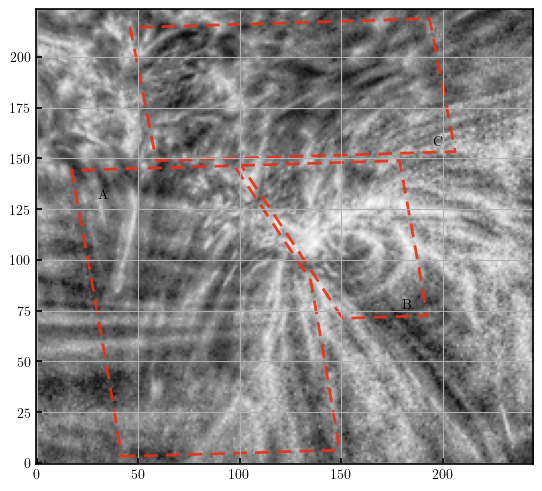

In [73]:
plt.close("all")
with plt.rc_context(ms_style_dict):
    fig = plt.figure(layout="constrained")
    ax = fig.add_subplot()
    ax.imshow(hri_pr_noproj_array[hrieuv_index_], cmap="Greys_r",
    origin="lower")

    for verts_ in (roiA_verts, roiB_verts, roiC_verts):
        with propagate_with_solar_surface():
            verts_new_ = convert_verts(verts_, wcs1=target_wcs, wcs2=hrieuv_noproj_wcs)    
        poly_ = Polygon(
            verts_new_, closed=True,
            facecolor='none', 
            edgecolor='#E83015', lw=2,
            ls=(0,(5,3)), alpha=0.9,
            joinstyle='round',
        )

        ax.add_patch(poly_)
    ax.grid("on")
    ax.text(30, 135, "A", ha="left", va="top")
    ax.text(185, 75, "B", ha="right", va="bottom")
    ax.text(200, 155, "C", ha="right", va="bottom")
    plt.show()

## Figure 2
---
Observations of different layers of the solar atmosphere within the VBI-B FOV. (a) Chromospheric fibrils in the VBI-B H$\beta$ channel; (b) WOW-enhanced HRIEUV in the Solar Orbiter helioprojective frame; (c) WOW-enhanced HRIEUV reprojected to the Earth-based helioprojective frame, with EUV counterparts (CPs) of fibrils highlighted by red arrows; (d) WOW-enhanced SDO/AIA 171 image, with a red arrow indicating a transition region (TR) loop that is also visible in IRIS 140\,nm and HRIEUV ; (e) WOW-enhanced IRIS/SJI 1400 channel; (f) VBI-R H$\alpha$, showing fewer fibril threads compared to H$\beta$; (g) VBI-B Ca II K, revealing blurred fibril emission at the edge of the plage; (h) VBI-B G-band exhibiting the pore and photospheric bright points; (i) VBI-R TiO. Panels (a) and (c--i) share the same FOV. Three Regions of Interest (ROIs) and six slits for further analysis are outlined in (a). The six slits, with their orientations altered to match the projection effects, are also shown in (b). 

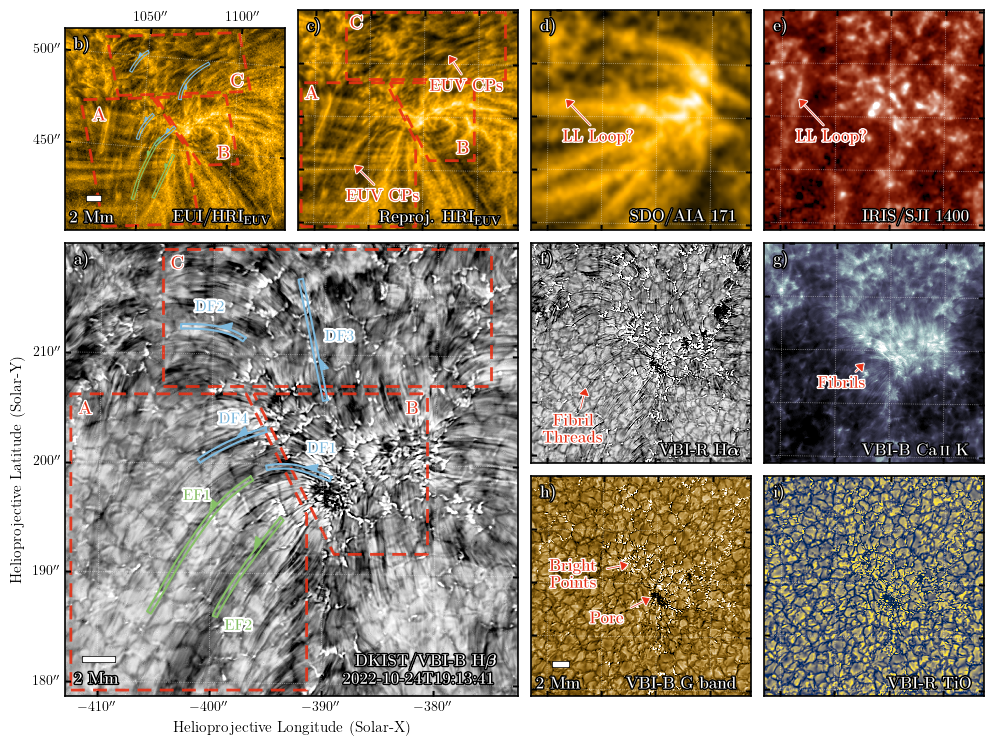

In [78]:
display(HTML('<a href="#notebook-top">Go to top</a>'))
display(HTML('<a id="figure-2"></a>'))

style = dict(show_points=False, show_curve=False, show_direction=True,
             direction_ratio=0.6, alpha=1.0)
style_A = dict(style, direction_size=100, linewidth=1.5)
style_B = dict(style, direction_size=5, linewidth=0.8)

plt.close("all")
with plt.rc_context(ms_style_dict):
    fig = plt.figure(figsize=(fig_x*fig_size_scale, fig_y*fig_size_scale))

    axes = {}

    axes["A"] = fig.add_axes([left_margin/fig_x, bottom_margin/fig_y,
            (2 + w_space)/fig_x, (2 + h_space)/fig_y],
            projection=target_wcs)

    imA = axes["A"].imshow(Hbeta_pr_set[Hbeta_index_], cmap="Greys_r",
                # norm=ImageNormalize(vmin=-0.05, vmax=1.5,
                # stretch=AsinhStretch(0.6)),
                norm=ImageNormalize(vmin=-0.1, vmax=1.1),
                interpolation="none", aspect=1, rasterized=True)

    for slit in (slit_df1, slit_df2, slit_df3, slit_df4):
        sip.plot_slit_position(axes["A"], slit, color="#7DB9DE", **style_A)
    for slit in (slit_ef1, slit_ef2):
        sip.plot_slit_position(axes["A"], slit, color="#86C166", **style_A)
    
    axes["A"].text(2050, 2150,
        r"\textbf{DF1}", ha="left", va="top", fontsize=11, color="#7DB9DE",
        alpha=1, path_effects=[path_effects.Stroke(linewidth=3, foreground="w"),
        path_effects.Normal()]
        )
    
    axes["A"].text(1100, 3350,
        r"\textbf{DF2}", ha="left", va="top", fontsize=11, color="#7DB9DE",
        alpha=1,
        path_effects=[path_effects.Stroke(linewidth=3, foreground="w"),
        path_effects.Normal()]
        )   

    axes["A"].text(2200, 3100,
        r"\textbf{DF3}", ha="left", va="top", fontsize=11, color="#7DB9DE",
        alpha=1,
        path_effects=[path_effects.Stroke(linewidth=3, foreground="w"),
        path_effects.Normal()]
        ) 

    axes["A"].text(1300, 2400,
        r"\textbf{DF4}", ha="left", va="top", fontsize=11, color="#7DB9DE",
        alpha=1,
        path_effects=[path_effects.Stroke(linewidth=3, foreground="w"),
        path_effects.Normal()]
        ) 

    
    axes["A"].text(1000, 1750,
        r"\textbf{EF1}", ha="left", va="top", fontsize=11, color="#86C166",
        alpha=1,
        path_effects=[path_effects.Stroke(linewidth=3, foreground="w"),
        path_effects.Normal()]
        )    

    axes["A"].text(1350, 650,
        r"\textbf{EF2}", ha="left", va="top", fontsize=11, color="#86C166",
        alpha=1,
        path_effects=[path_effects.Stroke(linewidth=3, foreground="w"),
        path_effects.Normal()]
        )  
    
    
    roiA_verts = np.array([[50,50], [2048,50],
        [2048, 1536], [1536, 2560],
        [50, 2560], [50, 50]])
    
    axes["A"].text(50+64, 2560 - 64,
        r"\textbf{A}", ha="left", va="top", fontsize=13, color="#E83015",
        alpha=1, path_effects=[path_effects.Stroke(linewidth=2, foreground="w"),
        path_effects.Normal()]
        )

    roiB_verts = np.array([[1536+64, 2560], [3072, 2560],
        [3072, 1200],
        [1536+64 - (2560 - 1200)*(1536 - 2048)/(2560 - 1536),1200]])
    
    axes["A"].text(3072 - 64, 2560 - 64,
        r"\textbf{B}", ha="right", va="top", fontsize=13, color="#E83015",
        alpha=1, path_effects=[path_effects.Stroke(linewidth=2, foreground="w"),
        path_effects.Normal()]
        )

    roiC_verts = np.array([[832, 2560+64], [3608, 2560+64],
        [3608, 3840 - 50], [832, 3840 - 50]])
    
    axes["A"].text(832 + 64, 3840 - 50 - 64,
        r"\textbf{C}", ha="left", va="top", fontsize=13, color="#E83015",
        alpha=1, path_effects=[path_effects.Stroke(linewidth=2, foreground="w"),
        path_effects.Normal()]
        )

    for verts_ in (roiA_verts, roiB_verts, roiC_verts):
        poly_ = Polygon(
            verts_, closed=True,
            facecolor='none', 
            edgecolor='#E83015', lw=2,
            ls=(0,(5,3)), alpha=0.9,
            joinstyle='round',
        )

        axes["A"].add_patch(poly_)

    
    sbA = wcs_scalebar(axes["A"], 2*u.Mm, corner="bottom left",
                label=r"\textbf{2 Mm}",
                dsun=get_earth(Hbeta_date_obs[Hbeta_index_]).radius,
                bbox_to_anchor=(0.02, 0.02, 0.15, 0.15),
                bbox_transform=axes["A"].transAxes,
                frame=False, 
                color="white", size_vertical=35,
                fontproperties={"size": 12},
                sep=8,
                pad=0,
                borderpad=0
                )
    
    fig.canvas.draw()
    
    sbA.txt_label._text.set_path_effects([
        path_effects.Stroke(linewidth=2, foreground='black'),
        path_effects.Normal()
    ])

    sbA.size_bar.get_children()[0].set_path_effects([
        path_effects.Stroke(linewidth=2, foreground='black'),
        path_effects.Normal()
    ])

    axes["A"].text(0.98, 0.02,
                   r"\textbf{DKIST/VBI-B H}$\boldsymbol{\beta}$" + \
                    "\n" + \
                   r"\textbf{{{}}}".format(Hbeta_date_obs[Hbeta_index_].strftime("%Y-%m-%dT%H:%M:%S")),
                   ha="right", va="bottom", size=12, color="w",
                   transform=axes["A"].transAxes,
                   path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
                   path_effects.Normal()]
                   )

    axes["B"] = fig.add_axes([left_margin/fig_x, (bottom_margin + 2 + 2*h_space)/fig_y,
                              1/fig_x, 1/fig_y],
                              projection=hrieuv_noproj_wcs)

    imB = axes["B"].imshow(hri_pr_noproj_array[hrieuv_index_],
                cmap="solar orbiterhri_euv174",
                interpolation="none", aspect=1, rasterized=True)
    axes["B"].set_anchor((1,0))

    axes["B"].text(0.98, 0.02,
                r"\textbf{EUI/HRI\textsubscript{EUV}}",
                ha="right", va="bottom", size=12, color="w",
                transform=axes["B"].transAxes,
                path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
                path_effects.Normal()]
                )

    sbB = wcs_scalebar(axes["B"], 2*u.Mm, corner="bottom left",
                label=r"\textbf{2 Mm}",
                # dsun=get_earth(Hbeta_date_obs[Hbeta_index_]).radius,
                bbox_to_anchor=(0.02, 0.02, 0.15, 0.15),
                bbox_transform=axes["B"].transAxes,
                frame=False, 
                color="white",
                size_vertical=35*2*hri_pr_noproj_array[hrieuv_index_].shape[1]/\
                    Hbeta_pr_set[Hbeta_index_].shape[1],
                fontproperties={"size": 12},
                sep=8,
                pad=0,
                borderpad=0
                )
    
    fig.canvas.draw()
    
    sbB.txt_label._text.set_path_effects([
        path_effects.Stroke(linewidth=2, foreground='black'),
        path_effects.Normal()
    ])

    sbB.size_bar.get_children()[0].set_path_effects([
        path_effects.Stroke(linewidth=2, foreground='black'),
        path_effects.Normal()
    ])

    for verts_ in (roiA_verts, roiB_verts, roiC_verts):
        with propagate_with_solar_surface():
            verts_new_ = convert_verts(verts_, wcs1=target_wcs, wcs2=hrieuv_noproj_wcs)    
        poly_ = Polygon(
            verts_new_, closed=True,
            facecolor='none', 
            edgecolor='#E83015', lw=2,
            ls=(0,(5,3)), alpha=0.9,
            joinstyle='round',
        )

        axes["B"].add_patch(poly_)

    axes["B"].text(30, 135, r"\textbf{A}", ha="left", va="top", 
        fontsize=13, color="#E83015",
        alpha=1, path_effects=[path_effects.Stroke(linewidth=2, foreground="w"),
        path_effects.Normal()])
    axes["B"].text(185, 75, r"\textbf{B}", ha="right", va="bottom",
        fontsize=13, color="#E83015",
        alpha=1, path_effects=[path_effects.Stroke(linewidth=2, foreground="w"),
        path_effects.Normal()])
    axes["B"].text(200, 155, r"\textbf{C}", ha="right", va="bottom",
        fontsize=13, color="#E83015",
        alpha=1, path_effects=[path_effects.Stroke(linewidth=2, foreground="w"),
        path_effects.Normal()])

    for slit in (slit_df1_p, slit_df2_p, slit_df3_p, slit_df4_p):
        sip.plot_slit_position(axes["B"], slit, color="#7DB9DE", **style_B)
    for slit in (slit_ef1_p, slit_ef2_p):
        sip.plot_slit_position(axes["B"], slit, color="#86C166", **style_B)

    axes["C"] = fig.add_axes([(left_margin + 1 + w_space)/fig_x,
                              (bottom_margin + 2 + 2*h_space)/fig_y,
                              1/fig_x, 1/fig_y],
                              projection=target_wcs_rebin)
    imC = axes["C"].imshow(hri_pr_set[hrieuv_index_],
                cmap="solar orbiterhri_euv174",
                interpolation="none", aspect=1,
                rasterized=True)

    axes["C"].text(0.98, 0.02,
            r"\textbf{Reproj. HRI\textsubscript{EUV}}",
            ha="right", va="bottom", size=12, color="w",
            transform=axes["C"].transAxes,
            path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
            path_effects.Normal()]
            )

    axes["C"].annotate(r"\textbf{EUV CPs}",
        xy=(0.68, 0.8), xycoords="axes fraction",
        xytext=(0.78, 0.65), textcoords="axes fraction",
        va="center", ha="center",
        arrowprops=dict(arrowstyle="-|>, head_length={:.3f}, head_width={:.3f}".format(0.7/2, 0.5/2),
        color="#E83015", lw=0.5,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]),
        color="#E83015", fontsize=12,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]
    )

    axes["C"].annotate(r"\textbf{EUV CPs}",
        xy=(0.25, 0.3), xycoords="axes fraction",
        xytext=(0.4, 0.15), textcoords="axes fraction",
        va="center", ha="center",
        arrowprops=dict(arrowstyle="-|>, head_length={:.3f}, head_width={:.3f}".format(0.7/2, 0.5/2),
        color="#E83015", lw=0.5,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]),
        color="#E83015", fontsize=12,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]
    )

    for verts_ in (roiA_verts, roiB_verts, roiC_verts):
        poly_ = Polygon(
            verts_/8., closed=True,
            facecolor='none', 
            edgecolor='#E83015', lw=2,
            ls=(0,(5,3)), alpha=0.9,
            joinstyle='round',
        )

        axes["C"].add_patch(poly_)

    axes["C"].text((50+64)/8., (2560 - 64)/8.,
        r"\textbf{A}", ha="left", va="top", fontsize=13, color="#E83015",
        alpha=1, path_effects=[path_effects.Stroke(linewidth=2, foreground="w"),
        path_effects.Normal()]
        )
    
    axes["C"].text((3072 - 64)/8., (1200 + 64)/8.,
        r"\textbf{B}", ha="right", va="bottom", fontsize=13, color="#E83015",
        alpha=1, path_effects=[path_effects.Stroke(linewidth=2, foreground="w"),
        path_effects.Normal()]
        )
    
    axes["C"].text((832 + 64)/8., (3840 - 50 - 64)/8.,
        r"\textbf{C}", ha="left", va="top", fontsize=13, color="#E83015",
        alpha=1, path_effects=[path_effects.Stroke(linewidth=2, foreground="w"),
        path_effects.Normal()]
        )

    axes["D"] = fig.add_axes([(left_margin + 2 + 2*w_space)/fig_x,
                              (bottom_margin + 2 + 2*h_space)/fig_y,
                              1/fig_x, 1/fig_y],
                              projection=target_wcs_rebin)
    imD = axes["D"].imshow(aia171_pr_set[aia171_index_], cmap="sdoaia171",
                interpolation="none", aspect=1, rasterized=True)
    axes["D"].text(0.98, 0.02,
            r"\textbf{SDO/AIA 171}",
            ha="right", va="bottom", size=12, color="w",
            transform=axes["D"].transAxes,
            path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
            path_effects.Normal()]
            )

    axes["D"].annotate(r"\textbf{LL Loop?}",
        xy=(0.15, 0.6), xycoords="axes fraction",
        xytext=(0.32, 0.42), textcoords="axes fraction",
        va="center", ha="center",
        arrowprops=dict(arrowstyle="-|>, head_length={:.3f}, head_width={:.3f}".format(0.7/2, 0.5/2),
        color="#E83015", lw=0.5,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]),
        color="#E83015", fontsize=12,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]
    )

    axes["E"] = fig.add_axes([(left_margin + 3 + 3*w_space)/fig_x,
                                 (bottom_margin + 2 + 2*h_space)/fig_y,
                                 1/fig_x, 1/fig_y],
                                 projection=target_wcs_rebin)
    imE = axes["E"].imshow(irissji_pr_set[iris_index_], cmap="irissji1400",
                norm=ImageNormalize(
                    vmin=np.nanpercentile(irissji_pr_set[iris_index_], 0.5),
                    vmax=np.nanpercentile(irissji_pr_set[iris_index_], 99.8)
                ),
                interpolation="none", aspect=1, rasterized=True)
    axes["E"].text(0.98, 0.02,
            r"\textbf{IRIS/SJI 1400}",
            ha="right", va="bottom", size=12, color="w",
            transform=axes["E"].transAxes,
            path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
            path_effects.Normal()]
            )

    axes["E"].annotate(r"\textbf{LL Loop?}",
        xy=(0.15, 0.6), xycoords="axes fraction",
        xytext=(0.32, 0.42), textcoords="axes fraction",
        va="center", ha="center",
        arrowprops=dict(arrowstyle="-|>, head_length={:.3f}, head_width={:.3f}".format(0.7/2, 0.5/2),
        color="#E83015", lw=0.5,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]),
        color="#E83015", fontsize=12,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]
    )
    axes["F"] = fig.add_axes([(left_margin + 2 + 2*w_space)/fig_x,
                                 (bottom_margin + 1 + h_space)/fig_y,
                                 1/fig_x, 1/fig_y],
                                 projection=target_wcs)
    imF = axes["F"].imshow(Halpha_pr_set[Halpha_index_], cmap="Greys_r",
                # norm=ImageNormalize(vmin=0.1, vmax=1.3, stretch=AsinhStretch(0.5)),
                norm=ImageNormalize(vmin=0.1, vmax=0.8),
                interpolation="none", aspect=1, rasterized=True)
    axes["F"].text(0.98, 0.02,
            r"\textbf{VBI-R H}$\boldsymbol{\alpha}$",
            ha="right", va="bottom", size=12, color="w",
            transform=axes["F"].transAxes,
            path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
            path_effects.Normal()]
            )

    axes["F"].annotate(r"\textbf{Fibril}" + "\n" + r"\textbf{Threads}",
        xy=(0.25, 0.35), xycoords="axes fraction",
        xytext=(0.2, 0.15), textcoords="axes fraction",
        va="center", ha="center",
        arrowprops=dict(arrowstyle="-|>, head_length={:.3f}, head_width={:.3f}".format(0.7/2, 0.5/2),
        color="#E83015", lw=0.5,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]),
        color="#E83015", fontsize=12,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]
    )

    axes["G"] = fig.add_axes([(left_margin + 3 + 3*w_space)/fig_x,
                              (bottom_margin + 1 + h_space)/fig_y,
                              1/fig_x, 1/fig_y],
                              projection=target_wcs)
    imG = axes["G"].imshow(CaIIK_pr_set[CaIIK_index_], cmap="bone",
                norm=ImageNormalize(vmin=0, vmax=1.3),
                interpolation="none", aspect=1, rasterized=True)
    axes["G"].text(0.98, 0.02,
            r"\textbf{VBI-B Ca\,\textsc{ii} K}",
            ha="right", va="bottom", size=12, color="w",
            transform=axes["G"].transAxes,
            path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
            path_effects.Normal()]
            )

    axes["G"].annotate(r"\textbf{Fibrils}" ,
        xy=(0.46, 0.46), xycoords="axes fraction",
        xytext=(0.36, 0.36), textcoords="axes fraction",
        va="center", ha="center",
        arrowprops=dict(arrowstyle="-|>, head_length={:.3f}, head_width={:.3f}".format(0.7/2, 0.5/2),
        color="#E83015", lw=0.5,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]),
        color="#E83015", fontsize=12,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]
    )

    axes["H"] = fig.add_axes([(left_margin + 2 + 2*w_space)/fig_x,
                              (bottom_margin)/fig_y,
                              1/fig_x, 1/fig_y],
                              projection=target_wcs)
    imH = axes["H"].imshow(Gband_pr_set[Gband_index_], cmap="irissji2796",
                norm=ImageNormalize(vmin=0, vmax=1),
                interpolation="none", aspect=1, rasterized=True)
    axes["H"].text(0.98, 0.02,
            r"\textbf{VBI-B G band}",
            ha="right", va="bottom", size=12, color="w",
            transform=axes["H"].transAxes,
            path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
            path_effects.Normal()]
            )

    sbH = wcs_scalebar(axes["H"], 2*u.Mm, corner="bottom left",
                label=r"\textbf{2 Mm}",
                dsun=get_earth(Hbeta_date_obs[Hbeta_index_]).radius,
                bbox_to_anchor=(0.02, 0.02, 0.3, 0.3),
                bbox_transform=axes["H"].transAxes,
                frame=False, 
                color="white", size_vertical=70,
                fontproperties={"size": 12},
                sep=8,
                pad=0,
                borderpad=0
                )
    
    axes["H"].annotate(r"\textbf{Pore}",
        xy=(0.55, 0.45), xycoords="axes fraction",
        xytext=(0.35, 0.35), textcoords="axes fraction",
        va="center", ha="center",
        arrowprops=dict(arrowstyle="-|>, head_length={:.3f}, head_width={:.3f}".format(0.7/2, 0.5/2),
        color="#E83015", lw=0.5,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]),
        color="#E83015", fontsize=12,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]
    )

    axes["H"].annotate(r"\textbf{Bright}" + "\n" + r"\textbf{Points}",
        xy=(0.45, 0.6), xycoords="axes fraction",
        xytext=(0.2, 0.55), textcoords="axes fraction",
        va="center", ha="center",
        arrowprops=dict(arrowstyle="-|>, head_length={:.3f}, head_width={:.3f}".format(0.7/2, 0.5/2),
        color="#E83015", lw=0.5,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]),
        color="#E83015", fontsize=12,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]
    )
    
    fig.canvas.draw()
    
    sbH.txt_label._text.set_path_effects([
        path_effects.Stroke(linewidth=2, foreground='black'),
        path_effects.Normal()
    ])

    sbH.size_bar.get_children()[0].set_path_effects([
        path_effects.Stroke(linewidth=2, foreground='black'),
        path_effects.Normal()
    ])

    axes["I"] = fig.add_axes([(left_margin + 3 + 3*w_space)/fig_x,
                              (bottom_margin)/fig_y,
                              1/fig_x, 1/fig_y],
                              projection=target_wcs)
    imI = axes["I"].imshow(TiO_pr_set[TiO_index_], cmap="cividis",
                norm=ImageNormalize(vmin=0, vmax=1),
                interpolation="none", aspect=1, rasterized=True)
    axes["I"].text(0.98, 0.02,
            r"\textbf{VBI-R TiO}",
            ha="right", va="bottom", size=12, color="w",
            transform=axes["I"].transAxes,
            path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
            path_effects.Normal()]
            )


    for ax_key in {"A", "B", "C", "D", "E", "F", "G", "H", "I"}:
        axes[ax_key].grid(True, color="w", ls=":", lw=0.5, alpha=0.7)

    for ax_key in {"A", "C", "D", "E", "F", "G", "H", "I"}:
        axes[ax_key].set_adjustable("box")

    for ax_key in {"C", "D", "E", "F", "G", "H", "I"}:
        axes[ax_key].coords[0].set_axislabel(" ", size=0, visible=False)
        axes[ax_key].coords[1].set_axislabel(" ", size=0, visible=False)
        axes[ax_key].coords[0].set_ticklabel_visible(False)
        axes[ax_key].coords[1].set_ticklabel_visible(False)

    axes["B"].coords[0].set_axislabel(" ", size=0, visible=False)
    axes["B"].coords[1].set_axislabel(" ", size=0, visible=False)
    axes["B"].coords[0].set_ticks(number=4)
    axes["B"].coords[1].set_ticks(spacing=50*u.arcsec)
    # this bug in astropy 7.1.0 https://github.com/astropy/astropy/issues/18576
    # requires us to manually set the tick label 
    axes["B"].coords[0].set_ticklabel_position("t")

    axes["A"].coords[0].set_axislabel(r"Helioprojective Longitude (Solar-X)", size=11)
    axes["A"].coords[1].set_axislabel(r"Helioprojective Latitude (Solar-Y)", size=11)

    axes["A"].text(0.02, 0.98, r"\textbf{a)}", ha="left", va="top", size=12, color="w",
            transform=axes["A"].transAxes,
            path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
            path_effects.Normal()])
    
    for ax_key in {"B", "C", "D", "E", "F", "G", "H", "I"}:
        axes[ax_key].text(0.04, 0.96, r"\textbf{{{})}}".format(ax_key.lower()),
            ha="left", va="top", size=12, color="w",
            transform=axes[ax_key].transAxes,
            path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
            path_effects.Normal()])


    fig.savefig("../../figs/ms_figure/all_channel_layout.pdf", dpi=300, bbox_inches="tight")
    fig.savefig("../../figs/ms_figure_png/all_channel_layout.png", dpi=300, bbox_inches="tight")
    plt.show(fig)

In [15]:
hri_pr_set[hrieuv_index_].shape

(480, 480)

## Figure 2 in dark mode

In [79]:
# a dark mode style
dm_fc = "#F3F4F3"
dm_bg = "#2D2F34"
ms_dm_style_dict = {'text.usetex': True, 'font.family': 'serif', 'axes.linewidth': 1.2,
                    'xtick.major.width': 1.2, 'xtick.major.size': 4,
                    'ytick.major.width': 1.2, 'ytick.major.size': 4,
                    'xtick.minor.width': 1.2, 'xtick.minor.size': 2,
                    'ytick.minor.width': 1.2, 'ytick.minor.size': 2,
                    'xtick.direction': 'in', 'ytick.direction': 'in',
                    'text.latex.preamble': r'\usepackage[T1]{fontenc}'
                    r'\usepackage{amsmath}' r'\usepackage{siunitx}'
                    r'\sisetup{detect-all=True}' r'\usepackage{fixltx2e}',
                    'lines.color': dm_fc, 'patch.edgecolor': dm_fc,
                    'text.color': dm_fc, 'axes.facecolor': dm_bg,
                    'axes.edgecolor': dm_fc, 'axes.labelcolor': dm_fc,
                    'axes.prop_cycle': plt.cycler(color=['#8dd3c7', '#feffb3', '#bfbbd9',
                    '#fa8174', '#81b1d2', '#fdb462', '#b3de69', '#bc82bd', '#ccebc4', '#ffed6f']),
                    'xtick.color': dm_fc, 'ytick.color': dm_fc,
                    'grid.color': dm_fc,
                    # 'figure.facecolor': dm_bg, 'figure.edgecolor': dm_bg,
                    # 'savefig.facecolor': dm_bg, 'savefig.edgecolor': dm_bg,
                    'figure.facecolor': "none", 'figure.edgecolor': "none",
                    'savefig.facecolor': "none", 'savefig.edgecolor': "none", 'savefig.transparent': True,
                    'axes.facecolor': "none", #'axes.edgecolor': "none",
                    'boxplot.boxprops.color': dm_fc,
                    'boxplot.capprops.color': dm_fc,
                    'boxplot.whiskerprops.color': dm_fc,
                    'boxplot.flierprops.color': dm_fc,
                    'boxplot.flierprops.markeredgecolor': dm_fc,} 

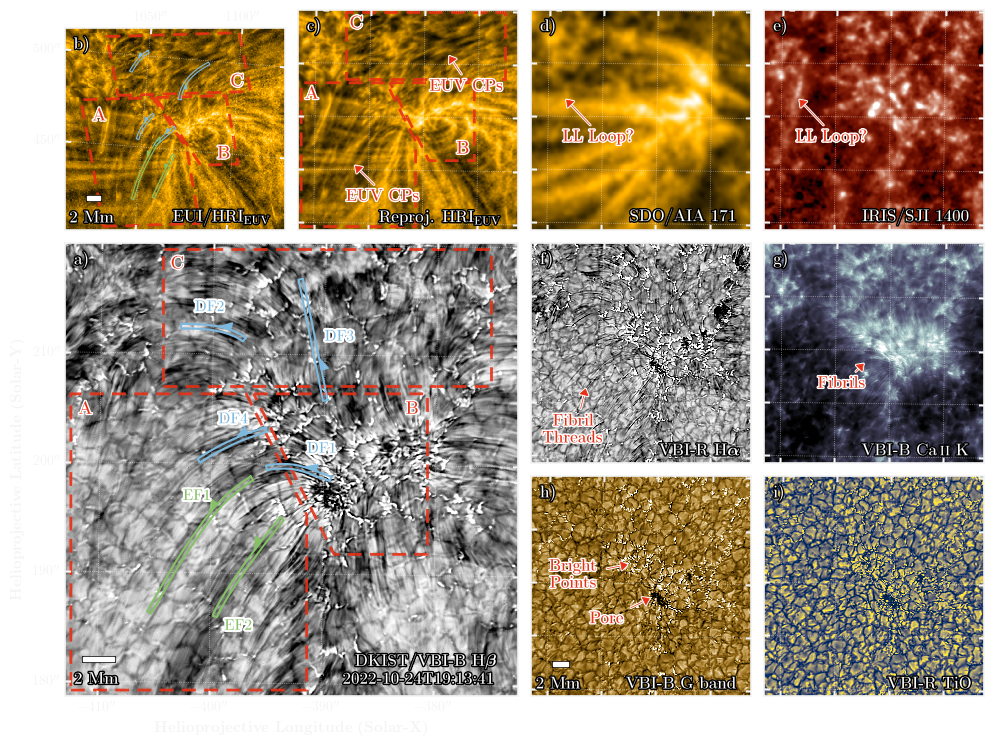

In [80]:
plt.close("all")
with plt.rc_context(ms_dm_style_dict):
    fig = plt.figure(figsize=(fig_x*fig_size_scale, fig_y*fig_size_scale))

    axes = {}

    axes["A"] = fig.add_axes([left_margin/fig_x, bottom_margin/fig_y,
            (2 + w_space)/fig_x, (2 + h_space)/fig_y],
            projection=target_wcs)

    imA = axes["A"].imshow(Hbeta_pr_set[Hbeta_index_], cmap="Greys_r",
                # norm=ImageNormalize(vmin=-0.05, vmax=1.5,
                # stretch=AsinhStretch(0.6)),
                norm=ImageNormalize(vmin=-0.1, vmax=1.1),
                interpolation="none", aspect=1, rasterized=True)

    for slit in (slit_df1, slit_df2, slit_df3, slit_df4):
        sip.plot_slit_position(axes["A"], slit, color="#7DB9DE", **style_A)
    for slit in (slit_ef1, slit_ef2):
        sip.plot_slit_position(axes["A"], slit, color="#86C166", **style_A)
    
    axes["A"].text(2050, 2150,
        r"\textbf{DF1}", ha="left", va="top", fontsize=11, color="#7DB9DE",
        alpha=1, path_effects=[path_effects.Stroke(linewidth=3, foreground="w"),
        path_effects.Normal()]
        )
    
    axes["A"].text(1100, 3350,
        r"\textbf{DF2}", ha="left", va="top", fontsize=11, color="#7DB9DE",
        alpha=1,
        path_effects=[path_effects.Stroke(linewidth=3, foreground="w"),
        path_effects.Normal()]
        )   

    axes["A"].text(2200, 3100,
        r"\textbf{DF3}", ha="left", va="top", fontsize=11, color="#7DB9DE",
        alpha=1,
        path_effects=[path_effects.Stroke(linewidth=3, foreground="w"),
        path_effects.Normal()]
        ) 

    axes["A"].text(1300, 2400,
        r"\textbf{DF4}", ha="left", va="top", fontsize=11, color="#7DB9DE",
        alpha=1,
        path_effects=[path_effects.Stroke(linewidth=3, foreground="w"),
        path_effects.Normal()]
        ) 

    
    axes["A"].text(1000, 1750,
        r"\textbf{EF1}", ha="left", va="top", fontsize=11, color="#86C166",
        alpha=1,
        path_effects=[path_effects.Stroke(linewidth=3, foreground="w"),
        path_effects.Normal()]
        )    

    axes["A"].text(1350, 650,
        r"\textbf{EF2}", ha="left", va="top", fontsize=11, color="#86C166",
        alpha=1,
        path_effects=[path_effects.Stroke(linewidth=3, foreground="w"),
        path_effects.Normal()]
        )  
    
    
    roiA_verts = np.array([[50,50], [2048,50],
        [2048, 1536], [1536, 2560],
        [50, 2560], [50, 50]])
    
    axes["A"].text(50+64, 2560 - 64,
        r"\textbf{A}", ha="left", va="top", fontsize=13, color="#E83015",
        alpha=1, path_effects=[path_effects.Stroke(linewidth=2, foreground="w"),
        path_effects.Normal()]
        )

    roiB_verts = np.array([[1536+64, 2560], [3072, 2560],
        [3072, 1200],
        [1536+64 - (2560 - 1200)*(1536 - 2048)/(2560 - 1536),1200]])
    
    axes["A"].text(3072 - 64, 2560 - 64,
        r"\textbf{B}", ha="right", va="top", fontsize=13, color="#E83015",
        alpha=1, path_effects=[path_effects.Stroke(linewidth=2, foreground="w"),
        path_effects.Normal()]
        )

    roiC_verts = np.array([[832, 2560+64], [3608, 2560+64],
        [3608, 3840 - 50], [832, 3840 - 50]])
    
    axes["A"].text(832 + 64, 3840 - 50 - 64,
        r"\textbf{C}", ha="left", va="top", fontsize=13, color="#E83015",
        alpha=1, path_effects=[path_effects.Stroke(linewidth=2, foreground="w"),
        path_effects.Normal()]
        )

    for verts_ in (roiA_verts, roiB_verts, roiC_verts):
        poly_ = Polygon(
            verts_, closed=True,
            facecolor='none', 
            edgecolor='#E83015', lw=2,
            ls=(0,(5,3)), alpha=0.9,
            joinstyle='round',
        )

        axes["A"].add_patch(poly_)

    
    sbA = wcs_scalebar(axes["A"], 2*u.Mm, corner="bottom left",
                label=r"\textbf{2 Mm}",
                dsun=get_earth(Hbeta_date_obs[Hbeta_index_]).radius,
                bbox_to_anchor=(0.02, 0.02, 0.15, 0.15),
                bbox_transform=axes["A"].transAxes,
                frame=False, 
                color="white", size_vertical=35,
                fontproperties={"size": 12},
                sep=8,
                pad=0,
                borderpad=0
                )
    
    fig.canvas.draw()
    
    sbA.txt_label._text.set_path_effects([
        path_effects.Stroke(linewidth=2, foreground='black'),
        path_effects.Normal()
    ])

    sbA.size_bar.get_children()[0].set_path_effects([
        path_effects.Stroke(linewidth=2, foreground='black'),
        path_effects.Normal()
    ])

    axes["A"].text(0.98, 0.02,
                   r"\textbf{DKIST/VBI-B H}$\boldsymbol{\beta}$" + \
                    "\n" + \
                   r"\textbf{{{}}}".format(Hbeta_date_obs[Hbeta_index_].strftime("%Y-%m-%dT%H:%M:%S")),
                   ha="right", va="bottom", size=12, color="w",
                   transform=axes["A"].transAxes,
                   path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
                   path_effects.Normal()]
                   )

    axes["B"] = fig.add_axes([left_margin/fig_x, (bottom_margin + 2 + 2*h_space)/fig_y,
                              1/fig_x, 1/fig_y],
                              projection=hrieuv_noproj_wcs)

    imB = axes["B"].imshow(hri_pr_noproj_array[hrieuv_index_],
                cmap="solar orbiterhri_euv174",
                interpolation="none", aspect=1, rasterized=True)
    axes["B"].set_anchor((1,0))

    axes["B"].text(0.98, 0.02,
                r"\textbf{EUI/HRI\textsubscript{EUV}}",
                ha="right", va="bottom", size=12, color="w",
                transform=axes["B"].transAxes,
                path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
                path_effects.Normal()]
                )

    sbB = wcs_scalebar(axes["B"], 2*u.Mm, corner="bottom left",
                label=r"\textbf{2 Mm}",
                # dsun=get_earth(Hbeta_date_obs[Hbeta_index_]).radius,
                bbox_to_anchor=(0.02, 0.02, 0.15, 0.15),
                bbox_transform=axes["B"].transAxes,
                frame=False, 
                color="white",
                size_vertical=35*2*hri_pr_noproj_array[hrieuv_index_].shape[1]/\
                    Hbeta_pr_set[Hbeta_index_].shape[1],
                fontproperties={"size": 12},
                sep=8,
                pad=0,
                borderpad=0
                )
    
    fig.canvas.draw()
    
    sbB.txt_label._text.set_path_effects([
        path_effects.Stroke(linewidth=2, foreground='black'),
        path_effects.Normal()
    ])

    sbB.size_bar.get_children()[0].set_path_effects([
        path_effects.Stroke(linewidth=2, foreground='black'),
        path_effects.Normal()
    ])

    for verts_ in (roiA_verts, roiB_verts, roiC_verts):
        with propagate_with_solar_surface():
            verts_new_ = convert_verts(verts_, wcs1=target_wcs, wcs2=hrieuv_noproj_wcs)    
        poly_ = Polygon(
            verts_new_, closed=True,
            facecolor='none', 
            edgecolor='#E83015', lw=2,
            ls=(0,(5,3)), alpha=0.9,
            joinstyle='round',
        )

        axes["B"].add_patch(poly_)

    axes["B"].text(30, 135, r"\textbf{A}", ha="left", va="top", 
        fontsize=13, color="#E83015",
        alpha=1, path_effects=[path_effects.Stroke(linewidth=2, foreground="w"),
        path_effects.Normal()])
    axes["B"].text(185, 75, r"\textbf{B}", ha="right", va="bottom",
        fontsize=13, color="#E83015",
        alpha=1, path_effects=[path_effects.Stroke(linewidth=2, foreground="w"),
        path_effects.Normal()])
    axes["B"].text(200, 155, r"\textbf{C}", ha="right", va="bottom",
        fontsize=13, color="#E83015",
        alpha=1, path_effects=[path_effects.Stroke(linewidth=2, foreground="w"),
        path_effects.Normal()])

    for slit in (slit_df1_p, slit_df2_p, slit_df3_p, slit_df4_p):
        sip.plot_slit_position(axes["B"], slit, color="#7DB9DE", **style_B)
    for slit in (slit_ef1_p, slit_ef2_p):
        sip.plot_slit_position(axes["B"], slit, color="#86C166", **style_B)

    axes["C"] = fig.add_axes([(left_margin + 1 + w_space)/fig_x,
                              (bottom_margin + 2 + 2*h_space)/fig_y,
                              1/fig_x, 1/fig_y],
                              projection=target_wcs_rebin)
    imC = axes["C"].imshow(hri_pr_set[hrieuv_index_],
                cmap="solar orbiterhri_euv174",
                interpolation="none", aspect=1,
                rasterized=True)

    axes["C"].text(0.98, 0.02,
            r"\textbf{Reproj. HRI\textsubscript{EUV}}",
            ha="right", va="bottom", size=12, color="w",
            transform=axes["C"].transAxes,
            path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
            path_effects.Normal()]
            )

    axes["C"].annotate(r"\textbf{EUV CPs}",
        xy=(0.68, 0.8), xycoords="axes fraction",
        xytext=(0.78, 0.65), textcoords="axes fraction",
        va="center", ha="center",
        arrowprops=dict(arrowstyle="-|>, head_length={:.3f}, head_width={:.3f}".format(0.7/2, 0.5/2),
        color="#E83015", lw=0.5,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]),
        color="#E83015", fontsize=12,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]
    )

    axes["C"].annotate(r"\textbf{EUV CPs}",
        xy=(0.25, 0.3), xycoords="axes fraction",
        xytext=(0.4, 0.15), textcoords="axes fraction",
        va="center", ha="center",
        arrowprops=dict(arrowstyle="-|>, head_length={:.3f}, head_width={:.3f}".format(0.7/2, 0.5/2),
        color="#E83015", lw=0.5,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]),
        color="#E83015", fontsize=12,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]
    )

    for verts_ in (roiA_verts, roiB_verts, roiC_verts):
        poly_ = Polygon(
            verts_/8., closed=True,
            facecolor='none', 
            edgecolor='#E83015', lw=2,
            ls=(0,(5,3)), alpha=0.9,
            joinstyle='round',
        )

        axes["C"].add_patch(poly_)

    axes["C"].text((50+64)/8., (2560 - 64)/8.,
        r"\textbf{A}", ha="left", va="top", fontsize=13, color="#E83015",
        alpha=1, path_effects=[path_effects.Stroke(linewidth=2, foreground="w"),
        path_effects.Normal()]
        )
    
    axes["C"].text((3072 - 64)/8., (1200 + 64)/8.,
        r"\textbf{B}", ha="right", va="bottom", fontsize=13, color="#E83015",
        alpha=1, path_effects=[path_effects.Stroke(linewidth=2, foreground="w"),
        path_effects.Normal()]
        )
    
    axes["C"].text((832 + 64)/8., (3840 - 50 - 64)/8.,
        r"\textbf{C}", ha="left", va="top", fontsize=13, color="#E83015",
        alpha=1, path_effects=[path_effects.Stroke(linewidth=2, foreground="w"),
        path_effects.Normal()]
        )

    axes["D"] = fig.add_axes([(left_margin + 2 + 2*w_space)/fig_x,
                              (bottom_margin + 2 + 2*h_space)/fig_y,
                              1/fig_x, 1/fig_y],
                              projection=target_wcs_rebin)
    imD = axes["D"].imshow(aia171_pr_set[aia171_index_], cmap="sdoaia171",
                interpolation="none", aspect=1, rasterized=True)
    axes["D"].text(0.98, 0.02,
            r"\textbf{SDO/AIA 171}",
            ha="right", va="bottom", size=12, color="w",
            transform=axes["D"].transAxes,
            path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
            path_effects.Normal()]
            )

    axes["D"].annotate(r"\textbf{LL Loop?}",
        xy=(0.15, 0.6), xycoords="axes fraction",
        xytext=(0.32, 0.42), textcoords="axes fraction",
        va="center", ha="center",
        arrowprops=dict(arrowstyle="-|>, head_length={:.3f}, head_width={:.3f}".format(0.7/2, 0.5/2),
        color="#E83015", lw=0.5,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]),
        color="#E83015", fontsize=12,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]
    )

    axes["E"] = fig.add_axes([(left_margin + 3 + 3*w_space)/fig_x,
                                 (bottom_margin + 2 + 2*h_space)/fig_y,
                                 1/fig_x, 1/fig_y],
                                 projection=target_wcs_rebin)
    imE = axes["E"].imshow(irissji_pr_set[iris_index_], cmap="irissji1400",
                norm=ImageNormalize(
                    vmin=np.nanpercentile(irissji_pr_set[iris_index_], 0.5),
                    vmax=np.nanpercentile(irissji_pr_set[iris_index_], 99.8)
                ),
                interpolation="none", aspect=1, rasterized=True)
    axes["E"].text(0.98, 0.02,
            r"\textbf{IRIS/SJI 1400}",
            ha="right", va="bottom", size=12, color="w",
            transform=axes["E"].transAxes,
            path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
            path_effects.Normal()]
            )

    axes["E"].annotate(r"\textbf{LL Loop?}",
        xy=(0.15, 0.6), xycoords="axes fraction",
        xytext=(0.32, 0.42), textcoords="axes fraction",
        va="center", ha="center",
        arrowprops=dict(arrowstyle="-|>, head_length={:.3f}, head_width={:.3f}".format(0.7/2, 0.5/2),
        color="#E83015", lw=0.5,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]),
        color="#E83015", fontsize=12,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]
    )
    axes["F"] = fig.add_axes([(left_margin + 2 + 2*w_space)/fig_x,
                                 (bottom_margin + 1 + h_space)/fig_y,
                                 1/fig_x, 1/fig_y],
                                 projection=target_wcs)
    imF = axes["F"].imshow(Halpha_pr_set[Halpha_index_], cmap="Greys_r",
                # norm=ImageNormalize(vmin=0.1, vmax=1.3, stretch=AsinhStretch(0.5)),
                norm=ImageNormalize(vmin=0.1, vmax=0.8),
                interpolation="none", aspect=1, rasterized=True)
    axes["F"].text(0.98, 0.02,
            r"\textbf{VBI-R H}$\boldsymbol{\alpha}$",
            ha="right", va="bottom", size=12, color="w",
            transform=axes["F"].transAxes,
            path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
            path_effects.Normal()]
            )

    axes["F"].annotate(r"\textbf{Fibril}" + "\n" + r"\textbf{Threads}",
        xy=(0.25, 0.35), xycoords="axes fraction",
        xytext=(0.2, 0.15), textcoords="axes fraction",
        va="center", ha="center",
        arrowprops=dict(arrowstyle="-|>, head_length={:.3f}, head_width={:.3f}".format(0.7/2, 0.5/2),
        color="#E83015", lw=0.5,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]),
        color="#E83015", fontsize=12,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]
    )

    axes["G"] = fig.add_axes([(left_margin + 3 + 3*w_space)/fig_x,
                              (bottom_margin + 1 + h_space)/fig_y,
                              1/fig_x, 1/fig_y],
                              projection=target_wcs)
    imG = axes["G"].imshow(CaIIK_pr_set[CaIIK_index_], cmap="bone",
                norm=ImageNormalize(vmin=0, vmax=1.3),
                interpolation="none", aspect=1, rasterized=True)
    axes["G"].text(0.98, 0.02,
            r"\textbf{VBI-B Ca\,\textsc{ii} K}",
            ha="right", va="bottom", size=12, color="w",
            transform=axes["G"].transAxes,
            path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
            path_effects.Normal()]
            )

    axes["G"].annotate(r"\textbf{Fibrils}" ,
        xy=(0.46, 0.46), xycoords="axes fraction",
        xytext=(0.36, 0.36), textcoords="axes fraction",
        va="center", ha="center",
        arrowprops=dict(arrowstyle="-|>, head_length={:.3f}, head_width={:.3f}".format(0.7/2, 0.5/2),
        color="#E83015", lw=0.5,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]),
        color="#E83015", fontsize=12,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]
    )

    axes["H"] = fig.add_axes([(left_margin + 2 + 2*w_space)/fig_x,
                              (bottom_margin)/fig_y,
                              1/fig_x, 1/fig_y],
                              projection=target_wcs)
    imH = axes["H"].imshow(Gband_pr_set[Gband_index_], cmap="irissji2796",
                norm=ImageNormalize(vmin=0, vmax=1),
                interpolation="none", aspect=1, rasterized=True)
    axes["H"].text(0.98, 0.02,
            r"\textbf{VBI-B G band}",
            ha="right", va="bottom", size=12, color="w",
            transform=axes["H"].transAxes,
            path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
            path_effects.Normal()]
            )

    sbH = wcs_scalebar(axes["H"], 2*u.Mm, corner="bottom left",
                label=r"\textbf{2 Mm}",
                dsun=get_earth(Hbeta_date_obs[Hbeta_index_]).radius,
                bbox_to_anchor=(0.02, 0.02, 0.3, 0.3),
                bbox_transform=axes["H"].transAxes,
                frame=False, 
                color="white", size_vertical=70,
                fontproperties={"size": 12},
                sep=8,
                pad=0,
                borderpad=0
                )
    
    axes["H"].annotate(r"\textbf{Pore}",
        xy=(0.55, 0.45), xycoords="axes fraction",
        xytext=(0.35, 0.35), textcoords="axes fraction",
        va="center", ha="center",
        arrowprops=dict(arrowstyle="-|>, head_length={:.3f}, head_width={:.3f}".format(0.7/2, 0.5/2),
        color="#E83015", lw=0.5,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]),
        color="#E83015", fontsize=12,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]
    )

    axes["H"].annotate(r"\textbf{Bright}" + "\n" + r"\textbf{Points}",
        xy=(0.45, 0.6), xycoords="axes fraction",
        xytext=(0.2, 0.55), textcoords="axes fraction",
        va="center", ha="center",
        arrowprops=dict(arrowstyle="-|>, head_length={:.3f}, head_width={:.3f}".format(0.7/2, 0.5/2),
        color="#E83015", lw=0.5,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]),
        color="#E83015", fontsize=12,
        path_effects=[path_effects.Stroke(linewidth=2, foreground="white"),
            path_effects.Normal()]
    )
    
    fig.canvas.draw()
    
    sbH.txt_label._text.set_path_effects([
        path_effects.Stroke(linewidth=2, foreground='black'),
        path_effects.Normal()
    ])

    sbH.size_bar.get_children()[0].set_path_effects([
        path_effects.Stroke(linewidth=2, foreground='black'),
        path_effects.Normal()
    ])

    axes["I"] = fig.add_axes([(left_margin + 3 + 3*w_space)/fig_x,
                              (bottom_margin)/fig_y,
                              1/fig_x, 1/fig_y],
                              projection=target_wcs)
    imI = axes["I"].imshow(TiO_pr_set[TiO_index_], cmap="cividis",
                norm=ImageNormalize(vmin=0, vmax=1),
                interpolation="none", aspect=1, rasterized=True)
    axes["I"].text(0.98, 0.02,
            r"\textbf{VBI-R TiO}",
            ha="right", va="bottom", size=12, color="w",
            transform=axes["I"].transAxes,
            path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
            path_effects.Normal()]
            )


    for ax_key in {"A", "B", "C", "D", "E", "F", "G", "H", "I"}:
        axes[ax_key].grid(True, color="w", ls=":", lw=0.5, alpha=0.7)

    for ax_key in {"A", "C", "D", "E", "F", "G", "H", "I"}:
        axes[ax_key].set_adjustable("box")

    for ax_key in {"C", "D", "E", "F", "G", "H", "I"}:
        axes[ax_key].coords[0].set_axislabel(" ", size=0, visible=False)
        axes[ax_key].coords[1].set_axislabel(" ", size=0, visible=False)
        axes[ax_key].coords[0].set_ticklabel_visible(False)
        axes[ax_key].coords[1].set_ticklabel_visible(False)

    axes["B"].coords[0].set_axislabel(" ", size=0, visible=False)
    axes["B"].coords[1].set_axislabel(" ", size=0, visible=False)
    axes["B"].coords[0].set_ticks(number=4)
    axes["B"].coords[1].set_ticks(spacing=50*u.arcsec)
    # this bug in astropy 7.1.0 https://github.com/astropy/astropy/issues/18576
    # requires us to manually set the tick label 
    axes["B"].coords[0].set_ticklabel_position("t")

    axes["A"].coords[0].set_axislabel(r"\textbf{Helioprojective Longitude (Solar-X)}", size=11)
    axes["A"].coords[1].set_axislabel(r"\textbf{Helioprojective Latitude (Solar-Y)}", size=11)

    axes["A"].text(0.02, 0.98, r"\textbf{a)}", ha="left", va="top", size=12, color="w",
            transform=axes["A"].transAxes,
            path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
            path_effects.Normal()])
    
    for ax_key in {"B", "C", "D", "E", "F", "G", "H", "I"}:
        axes[ax_key].text(0.04, 0.96, r"\textbf{{{})}}".format(ax_key.lower()),
            ha="left", va="top", size=12, color="w",
            transform=axes[ax_key].transAxes,
            path_effects=[path_effects.Stroke(linewidth=2, foreground="black"),
            path_effects.Normal()])


    fig.savefig("../../figs/ms_figure_dm/all_channel_layout_dm.pdf", dpi=300, bbox_inches="tight")
    fig.savefig("../../figs/ms_figure_dm_png/all_channel_layout_dm.png", dpi=300, bbox_inches="tight")
    plt.show(fig)